# Question 6: Error analysis

Which characteristics of the sentence pairs predict whether a system gets them right and do these differ between our major design choices?

We use the predictions saved during crossvalidation: every pair was predicted once, by the model of the fold where it was in the validation set. So for each system we know for all 57,401 pairs whether it was correct, without training anything new.

Systems:
- `pool_max`: Question 3 embed-and-pool with max pooling with no word order
- `lstm_base`: Question4 siamese BiLSTM on frozen GloVe
- `lstm_joint`: Question 4 one BiLSTM reading "sentence1 [SEP] sentence2"
- `lstm_best`: Question 4 best configuration (finetuned GloVe, hidden size 256, dropout 0.3)


In [14]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import confusion_matrix, precision_score, f1_score
from collections import Counter
from difflib import SequenceMatcher
from nltk.tokenize import TreebankWordTokenizer

from src.utils import load_datasets

train_df, dev_df, _ = load_datasets()
df = pd.concat([train_df, dev_df]).reset_index(drop=True)[["id", "sentence1", "sentence2", "label"]]

q3 = json.loads(Path("results/q3_glove.json").read_text())
q4 = json.loads(Path("results/q4_glove.json").read_text())

SYSTEMS = {
    "pool_max": q3["pool_max"],   
    "lstm_base": q4["base"],      
    "lstm_joint": q4["joint"],    
    "lstm_best": q4["combined"],  
}


folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=64).split(df, df["label"]))
df["fold"] = -1
for k, (_, val_idx) in enumerate(folds):
    df.loc[val_idx, "fold"] = k

for name, r in SYSTEMS.items():
    preds = np.array(r["predictions"])
    assert len(preds) == len(df) and (preds >= 0).all(), name
    df[f"pred_{name}"] = preds
    df[f"correct_{name}"] = (preds == df["label"]).astype(int)

    # accuracies recomputed per fold must equal the saved ones
    recomputed = [df.loc[val_idx, f"correct_{name}"].mean() for _, val_idx in folds]
    assert np.allclose(recomputed, r["accuracies"]), f"{name}: predictions do not match the pairs"

print(f"{len(df)} pairs, alignment check passed for {list(SYSTEMS)}")
display(df[[f"correct_{n}" for n in SYSTEMS]].mean().mul(100).round(2).rename("accuracy (%)"))
display(df.head())


57401 pairs, alignment check passed for ['pool_max', 'lstm_base', 'lstm_joint', 'lstm_best']


correct_pool_max      56.41
correct_lstm_base     84.28
correct_lstm_joint    71.19
correct_lstm_best     87.83
Name: accuracy (%), dtype: float64

,id,sentence1,sentence2,label,fold,pred_pool_max,correct_pool_max,pred_lstm_base,correct_lstm_base,pred_lstm_joint,correct_lstm_joint,pred_lstm_best,correct_lstm_best
0,1,"In Paris , in October 1560 , he secretly met t...","In October 1560 , he secretly met with the Eng...",0,1,0,1,0,1,0,1,0,1
1,2,The NBA season of 1975 -- 76 was the 30th seas...,The 1975 -- 76 season of the National Basketba...,1,1,1,1,1,1,1,1,1,1
2,3,"There are also specific discussions , public p...","There are also public discussions , profile sp...",0,3,1,0,0,1,0,1,0,1
3,4,When comparable rates of flow can be maintaine...,The results are high when comparable flow rate...,1,3,1,1,0,0,0,0,0,0
4,5,It is the seat of Zerendi District in Akmola R...,It is the seat of the district of Zerendi in A...,1,1,0,0,1,1,1,1,1,1


**Testing class specific errors (Recall, Precision, F1)**

In [15]:
rows = []

for name in SYSTEMS:
    y_true = df["label"].to_numpy()
    y_pred = df[f"pred_{name}"].to_numpy()

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    rows.append({
        "System": name,
        "Accuracy (%)": (y_true == y_pred).mean() * 100,
        "Recall non-paraphrase (%)": tn / (tn + fp) * 100,
        "Recall paraphrase (%)": tp / (tp + fn) * 100,
        "Precision paraphrase (%)": precision_score(y_true, y_pred) * 100,
        "F1 paraphrase (%)": f1_score(y_true, y_pred) * 100,
        "False negatives": fn,
        "False positives": fp,
    })

class_results = pd.DataFrame(rows)
display(class_results.round(2))

,System,Accuracy (%),Recall non-paraphrase (%),Recall paraphrase (%),Precision paraphrase (%),F1 paraphrase (%),False negatives,False positives
0,pool_max,56.41,91.44,12.17,52.96,19.79,22281,2742
1,lstm_base,84.28,87.10,80.73,83.21,81.95,4889,4133
2,lstm_joint,71.19,79.46,60.74,70.07,65.07,9959,6581
3,lstm_best,87.83,90.12,84.94,87.19,86.05,3821,3166


**Lexical overlap and word order changes comparison**

In [16]:
tokenizer = TreebankWordTokenizer()

def tokenize(text):
    return [
        t.lower()
        for t in tokenizer.tokenize(text)
        if any(c.isalnum() for c in t)
    ]

FUNCTION_WORDS = {
    "a", "an", "the", "in", "on", "at", "by", "from",
    "of", "to", "for", "with", "as", "into", "over",
    "under", "before", "after", "and", "or", "but"
}

NEGATIONS = {
    "not", "n't", "never", "no", "neither", "nor", "without"
}

def extract_features(row):
    t1 = tokenize(row["sentence1"])
    t2 = tokenize(row["sentence2"])

    c1, c2 = Counter(t1), Counter(t2)

    shared = sum((c1 & c2).values())
    total = sum((c1 | c2).values())

    only1 = list((c1 - c2).elements())
    only2 = list((c2 - c1).elements())

    same_words = c1 == c2
    same_order = t1 == t2

    return pd.Series({
        "length_mean": (len(t1) + len(t2)) / 2,
        "length_difference": abs(len(t1) - len(t2)),
        "lexical_overlap": shared / total if total else 1.0,
        "same_words": same_words,
        "reordered": same_words and not same_order,
        "order_similarity": SequenceMatcher(
            None, t1, t2, autojunk=False
        ).ratio(),
        "one_substitution": len(only1) == 1 and len(only2) == 1,
        "function_word_substitution": (
            len(only1) == 1
            and len(only2) == 1
            and only1[0] in FUNCTION_WORDS
            and only2[0] in FUNCTION_WORDS
        ),
        "negation_difference": (
            Counter(t for t in t1 if t in NEGATIONS)
            != Counter(t for t in t2 if t in NEGATIONS)
        )
    })

features = df.apply(extract_features, axis=1)
df = pd.concat([df, features], axis=1)

In [17]:
rows = []

for name in SYSTEMS:
    for reordered in [False, True]:
        subset = df[df["reordered"] == reordered]

        for label in [0, 1]:
            group = subset[subset["label"] == label]

            rows.append({
                "System": name,
                "Reordered": reordered,
                "Label": label,
                "N": len(group),
                "Accuracy (%)": group[f"correct_{name}"].mean() * 100
            })

reorder_results = pd.DataFrame(rows)

display(
    reorder_results.pivot_table(
        index=["Reordered", "Label"],
        columns="System",
        values="Accuracy (%)"
    ).round(2)
)

display(
    reorder_results[
        reorder_results["System"] == "pool_max"
    ][["Reordered", "Label", "N"]]
)

System           lstm_base  lstm_best  lstm_joint  pool_max
Reordered Label                                            
False     0          87.21      89.65       79.01     91.39
          1          80.13      84.59       59.82     11.90
True      0          86.26      93.53       82.72     91.77
          1          89.67      90.18       74.65     16.29

,Reordered,Label,N
0,False,0,28155
1,False,1,23790
2,True,0,3878
3,True,1,1578


In [18]:
df["overlap_group"] = pd.cut(
    df["lexical_overlap"],
    bins=[-0.01, 0.5, 0.7, 0.85, 0.95, 1.01],
    labels=["less than 0.50", "0.50–0.70", "0.70–0.85", "0.85–0.95", " more than 0.95"]
)

overlap_results = (
    df.groupby(["overlap_group", "label"], observed=True)
      .agg(
          N=("label", "size"),
          pool_max=("correct_pool_max", "mean"),
          lstm_base=("correct_lstm_base", "mean"),
          lstm_joint=("correct_lstm_joint", "mean"),
          lstm_best=("correct_lstm_best", "mean")
      )
)

display(overlap_results.round(3))

N  pool_max  lstm_base  lstm_joint  lstm_best
overlap_group   label                                                   
less than 0.50  0         27     0.963      0.963       1.000      0.963
                1          8     0.250      0.875       0.500      1.000
0.50–0.70       0        319     0.912      0.934       0.837      0.925
                1         44     0.341      0.659       0.682      0.705
0.70–0.85       0      12001     0.917      0.878       0.793      0.900
                1       9168     0.112      0.717       0.539      0.787
0.85–0.95       0      14784     0.911      0.868       0.786      0.892
                1      13611     0.124      0.846       0.629      0.877
 more than 0.95 0       4902     0.920      0.859       0.822      0.930
                1       2537     0.139      0.929       0.737      0.931

In [19]:
feature_names = [
    "one_substitution",
    "function_word_substitution",
    "negation_difference",
    "reordered",
]

rows = []

for feature in feature_names:
    for value in [False, True]:
        group = df[df[feature] == value]

        row = {
            "Feature": feature,
            "Value": value,
            "N": len(group),
            "Paraphrase (%)": group["label"].mean() * 100,
        }

        for name in SYSTEMS:
            row[f"{name} (%)"] = (
                group[f"correct_{name}"].mean() * 100
            )

        rows.append(row)

feature_results = pd.DataFrame(rows)
display(feature_results.round(2))

,Feature,Value,N,Paraphrase (%),pool_max (%),lstm_base (%),lstm_joint (%),lstm_best (%)
0,one_substitution,False,43556,42.83,57.57,84.09,71.56,88.04
1,one_substitution,True,13845,48.49,52.73,84.89,70.00,87.17
2,function_word_substitution,False,55508,44.17,56.45,84.12,71.02,87.65
3,function_word_substitution,True,1893,44.90,55.20,89.12,75.91,92.97
4,negation_difference,False,57325,44.20,56.40,84.29,71.18,87.83
5,negation_difference,True,76,39.47,57.89,77.63,72.37,82.89
6,reordered,False,51945,45.80,54.99,83.97,70.22,87.33
7,reordered,True,5456,28.92,69.94,87.24,80.39,92.56


**Testing if function-word changes, negation and sentence length influence model performance**

In [20]:
df["length_group"] = pd.cut(
    df["length_mean"],
    bins=[0, 10, 20, 30, 50, float("inf")],
    labels=["1–10", "11–20", "21–30", "31–50", ">50"]
)

length_results = (
    df.groupby(["length_group", "label"], observed=True)
      .agg(
          N=("label", "size"),
          pool_max=("correct_pool_max", "mean"),
          lstm_base=("correct_lstm_base", "mean"),
          lstm_joint=("correct_lstm_joint", "mean"),
          lstm_best=("correct_lstm_best", "mean")
      )
)

display(length_results.round(3))

N  pool_max  lstm_base  lstm_joint  lstm_best
length_group label                                                   
1–10         0        938     0.830      0.862       0.760      0.910
             1        844     0.252      0.770       0.731      0.794
11–20        0      18736     0.907      0.880       0.800      0.909
             1      15178     0.133      0.815       0.640      0.846
21–30        0      12343     0.932      0.857       0.790      0.889
             1       9340     0.091      0.798       0.543      0.860
31–50        0         16     1.000      0.812       0.562      0.875
             1          6     0.000      0.667       0.500      0.833

**Examples all models got wrong**

In [21]:
correct_columns = [
    f"correct_{name}" for name in SYSTEMS
]

df["all_wrong"] = (df[correct_columns].sum(axis=1) == 0)

display(
    df.loc[
        df["all_wrong"],
        ["sentence1", "sentence2", "label",
         "lexical_overlap", "reordered"]].head(15)
)

,sentence1,sentence2,label,lexical_overlap,reordered
20,Pluto was classified as the planet when the Gr...,Note : Pluto was classified as a planet when t...,0,0.863636,False
28,Akshuat dendropark ( Russian : Акшуатский денд...,Akshuat dendropark ( Russian : Акшуатский денд...,1,0.928571,False
31,"WORHP , also referred to as eNLP ( European NL...","WORHP , also referred to as eNLP ( European NL...",1,0.851852,False
36,These geographically correspond to the traditi...,These geographically roughly correspond to the...,1,0.888889,False
44,Taieri is a former parliamentary electorate in...,Taieri is a former parliamentary electorate in...,1,1.000000,True
96,The bones of Zrinski and Frankopan were found ...,The bones of Zrinski and Frankopan were found ...,1,0.925926,False
157,The company was then acquired the St. Louis an...,The company then was the St. Louis and Cairo R...,1,0.866667,False
177,The river Oraciu or Orociu is a tributary of t...,The Oraciu River or Orociu River is a tributar...,1,0.933333,False
219,The film was filmed in Red Rock Canyon State P...,The film was shot in California ( Red Rock Can...,1,0.866667,False
242,Container glass has a higher content of magnes...,Container glass has a higher magnesium oxide a...,1,0.851852,False


**Summary of the best BiLSTM improvements**

,Category,N,BiLSTM vs pooling,Best vs base BiLSTM
0,Reordered,5456,17.30,5.32
1,One substitution,13845,32.16,2.28
2,Function-word substitution,1893,33.91,3.86
3,Negation difference,76,19.74,5.26
4,High lexical overlap (more than 0.9),19605,30.23,3.54


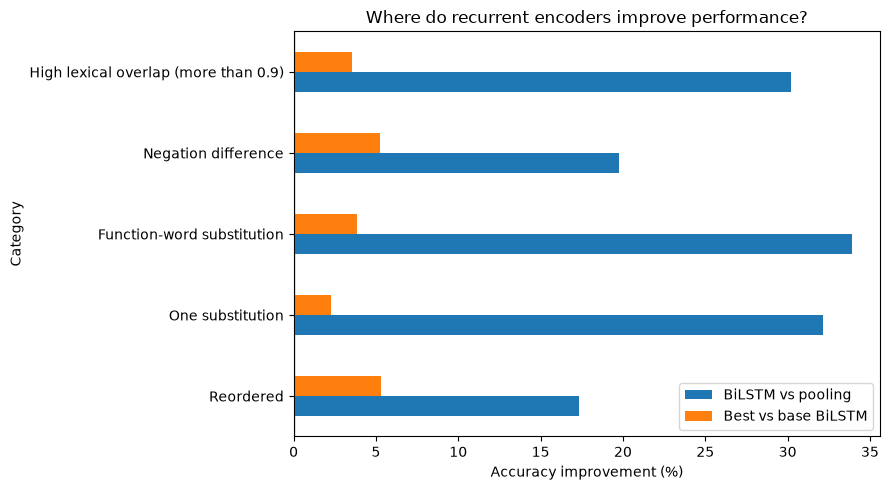

In [22]:
categories = {
    "Reordered": df["reordered"],
    "One substitution": df["one_substitution"],
    "Function-word substitution": df["function_word_substitution"],
    "Negation difference": df["negation_difference"],
    "High lexical overlap (more than 0.9)": df["lexical_overlap"] >= 0.9,
}

gains = []

for name, mask in categories.items():
    group = df[mask]

    gains.append({
        "Category": name,
        "N": len(group),
        "BiLSTM vs pooling": (
            group["correct_lstm_base"].mean()
            - group["correct_pool_max"].mean()) * 100,
        "Best vs base BiLSTM": (
            group["correct_lstm_best"].mean()
            - group["correct_lstm_base"].mean()) * 100,
    })

gains_df = pd.DataFrame(gains)
display(gains_df.round(2))

ax = gains_df.set_index("Category")[
    ["BiLSTM vs pooling", "Best vs base BiLSTM"]].plot.barh(figsize=(9, 5))

ax.axvline(0, color="gray", linewidth=1)
ax.set_xlabel("Accuracy improvement (%)")
ax.set_title("Where do recurrent encoders improve performance?")
plt.tight_layout()
plt.show()

**Using a logistic regression model to predict if a classifier gets the input correct**

In [23]:
feature_columns = [
    "length_mean",
    "length_difference",
    "lexical_overlap",
    "order_similarity",
    "reordered",
    "one_substitution",
    "function_word_substitution",
    "negation_difference",
]

X = df[feature_columns].astype(float)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

coefficients = []

for name in SYSTEMS:
    y = df[f"correct_{name}"]

    model = LogisticRegression(
        l1_ratio=1,
        solver="liblinear",
        C=1.0,
        max_iter=2000)

    model.fit(X_scaled, y)

    coefficients.append(pd.Series(model.coef_[0], index=feature_columns, name=name))

coef_df = pd.DataFrame(coefficients)

display(coef_df.round(3))

,length_mean,length_difference,lexical_overlap,order_similarity,reordered,one_substitution,function_word_substitution,negation_difference
pool_max,0.217,-0.064,0.166,-1.073,0.162,0.004,-0.009,0.010
lstm_base,-0.036,-0.023,0.220,-0.130,-0.070,-0.028,0.072,-0.011
lstm_joint,-0.064,0.000,0.212,-0.422,0.034,-0.037,0.052,0.010
lstm_best,0.031,-0.009,0.253,-0.179,0.013,-0.067,0.126,-0.009


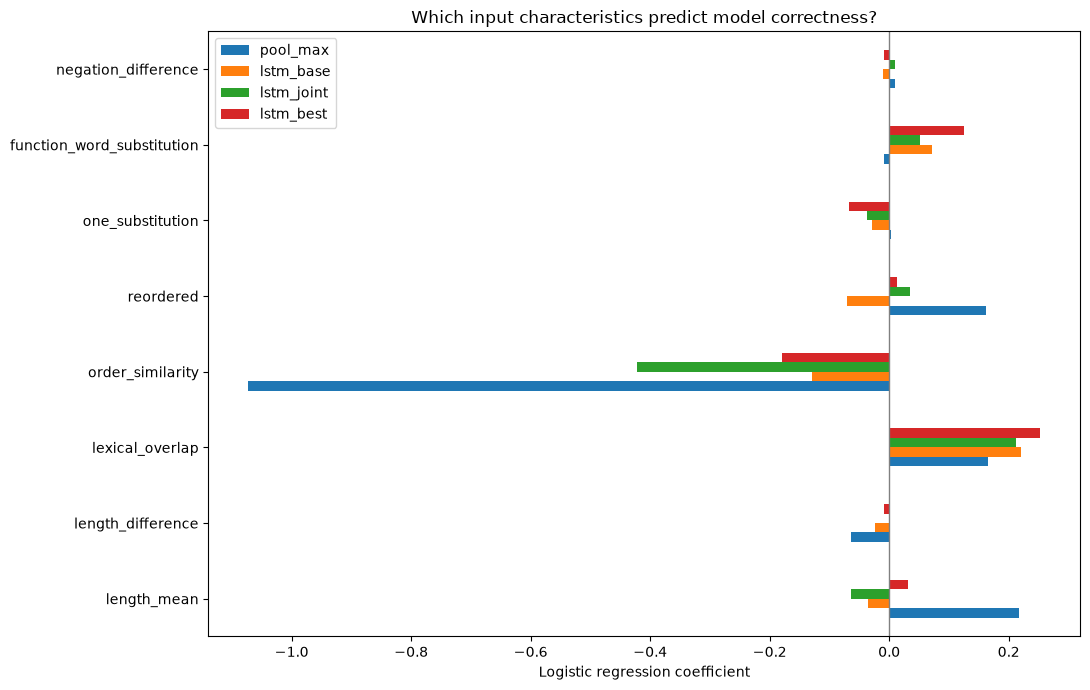

In [24]:
ax = coef_df.T.plot.barh(figsize=(11, 7))

ax.axvline(0, color="gray", linewidth=1)
ax.set_xlabel("Logistic regression coefficient")
ax.set_title("Which input characteristics predict model correctness?")

plt.tight_layout()
plt.show()

**Logistic regression per class**

Pooling predicts nonparaphrase for almost every pair so for pooling being correct mostly means the pair is a nonparaphrase. Order similarity is also correlated with the label so we fit the regression separately for each class.

In [25]:
rows = []
for label, label_name in [(0, "non-paraphrase"), (1, "paraphrase")]:
    subset = df[df["label"] == label]
    X = StandardScaler().fit_transform(subset[feature_columns].astype(float))
    for name in SYSTEMS:
        model = LogisticRegression(solver="liblinear", l1_ratio=1, C=1.0, max_iter=2000)
        model.fit(X, subset[f"correct_{name}"])
        rows.append(pd.Series(model.coef_[0], index=feature_columns, name=(label_name, name)))

class_coef_df = pd.DataFrame(rows)
display(class_coef_df.round(3))

length_mean  length_difference  lexical_overlap  \
non-paraphrase pool_max          0.318             -0.081           -0.035   
               lstm_base         0.087             -0.059            0.085   
               lstm_joint        0.144             -0.000            0.149   
               lstm_best         0.112             -0.078            0.232   
paraphrase     pool_max         -0.294              0.017            0.026   
               lstm_base        -0.083             -0.007            0.418   
               lstm_joint       -0.257              0.010            0.199   
               lstm_best         0.034              0.029            0.357   

                           order_similarity  reordered  one_substitution  \
non-paraphrase pool_max              -0.132      0.072            -0.020   
               lstm_base             -0.888      0.025             0.000   
               lstm_joint            -0.753      0.099            -0.043   
               lstm_best             -1.094      0.144            -0.065   
paraphrase     pool_max              -0.121      0.013            -0.020   
               lstm_base              0.530     -0.084            -0.060   
               lstm_joint             0.166      0.001            -0.036   
               lstm_best              0.467     -0.078            -0.066   

                           function_word_substitution  negation_difference  
non-paraphrase pool_max                         0.056                0.024  
               lstm_base                        0.009               -0.015  
               lstm_joint                       0.041                0.018  
               lstm_best                        0.060               -0.004  
paraphrase     pool_max                        -0.076               -0.156  
               lstm_base                        0.110               -0.007  
               lstm_joint                       0.053                0.002  
               lstm_best                        0.165               -0.013

**Conclusion Q6**

Analysis features:
- The analysis consisted of lexical overlap, word reordering, sentence length, one-word and function-word substitutions and negation differences. It was compared how these features affect correctness across pooling, joint BiLSTM and Siamese BiLSTM models.

Main findings:
- Embed-and-pool mostly predicts non-paraphrases, correctly identifying 91.4% of them but only 12.2% of paraphrases. The best BiLSTM achieves 90.1% and 84.9% recall respectively, showing much better balance between classes.
- On 5456 pairs with identical words in different orders, pooling achieves 69.9% accuracy compared with 92.6% for the best BiLSTM. Pooling's accuracy mainly comes from predicting non-paraphrases, while the BiLSTM handles both classes well.
- One-word and function-word substitutions show large improvements from pooling to BiLSTM (+32.2 and +33.9 percent). Negation differences were too rare (76 pairs) for reliable conclusions, while sentence length showed no consistent pattern across models.
- Logistic regression found order similarity to be the strongest negative predictor of pooling correctness (-1.07), compared with -0.13 for the base BiLSTM. But this mostly reflects the label since pooling almost always predicts nonparaphrase and paraphrases keep their word order more often. Per class pooling barely reacts to order similarity but the BiLSTMs do. For them a nonparaphrase with almost the same word order is the hardest case and a paraphrase with the same order the easiest, so they are still fooled by surface similarity.

Future improvements:
- The main limitation of pooling is losing word-order information. Recurrent encoders address this and improve overall accuracy from 56.4% to 87.8%.
- We would prioritise architectures that model relationships between sentences more directly, such as cross-attention, and manually inspect the remaining BiLSTM errors to understand more subtle semantic and grammatical differences.
- The current analysis identifies statistical associations with errors, but manually categorizing more individual errors could help explain what the model still struggles with.